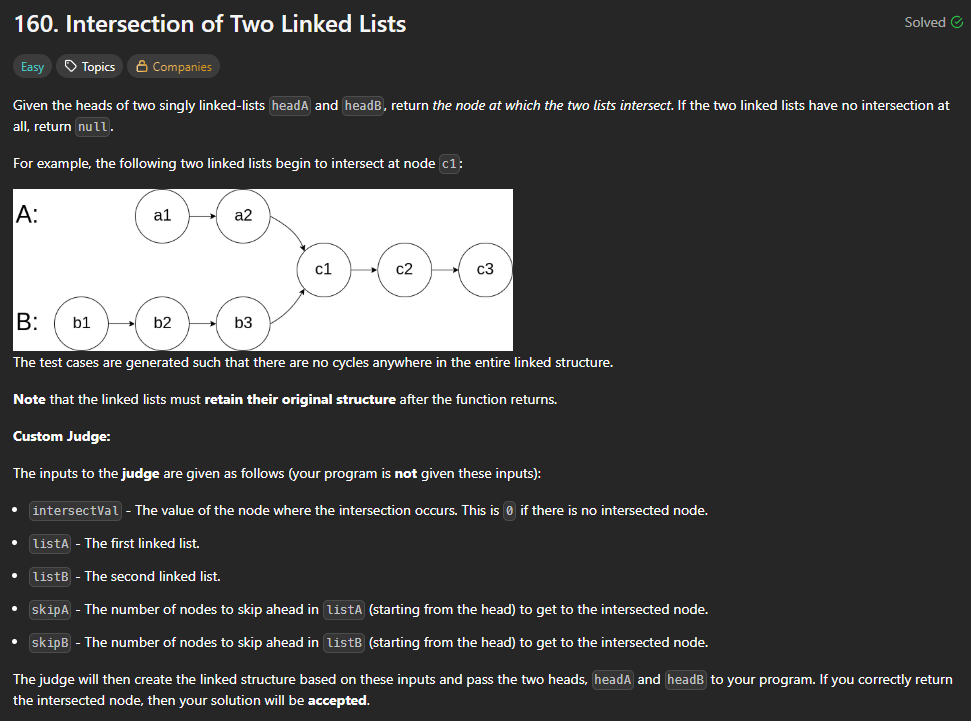

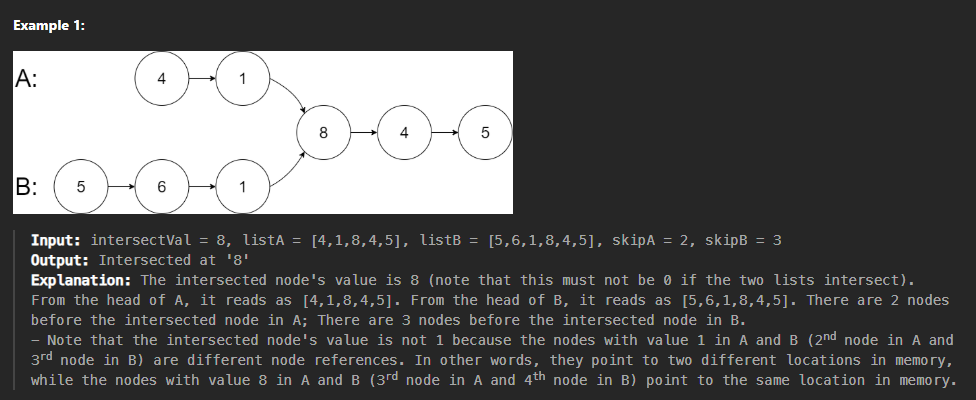

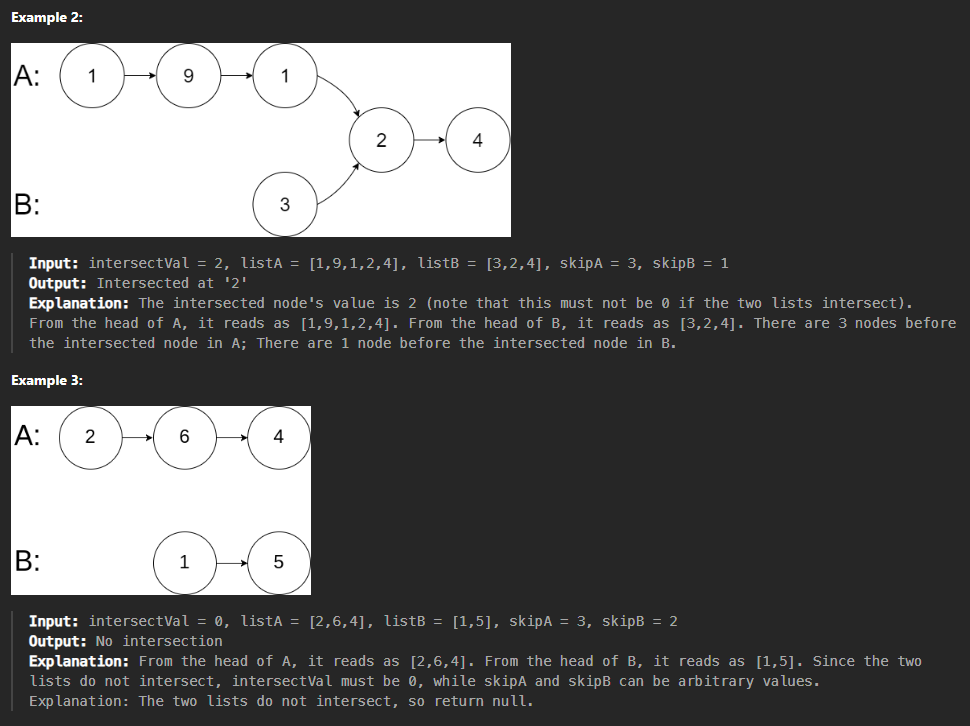

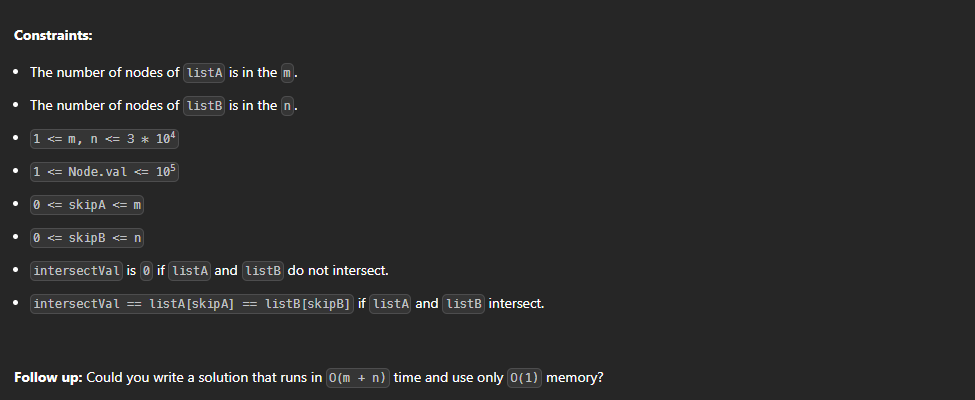

**1st approach**

In [ ]:
class ListNode:
  def __init__(self, val=0, next=None):
    self.val = val
    self.next = next


class Solution:
  def linkedListHelper(self, arrA, arrB):
    def build_list(arr):
      if not arr:
        return None
      head = ListNode(arr[0])
      curr = head
      for data in arr[1:]:
        curr.next = ListNode(data)
        curr = curr.next
      return head

    headA = build_list(arrA)
    headB = build_list(arrB)
    return headA, headB

  def getIntersectionNode(self, headA: ListNode | None, headB: ListNode | None) -> ListNode | None:
    currA = headA
    currB = headB
    la = 0
    lb = 0

    # Calculate lengths
    while currA is not None:
      la += 1
      currA = currA.next

    while currB is not None:
      lb += 1
      currB = currB.next

    # Reset my pointers to heads
    currA = headA
    currB = headB

    # then I will align start nodes to equal remaining distance
    if la > lb:
      eff = la - lb
      for _ in range(eff):
        currA = currA.next

    if lb > la:
      eff = lb - la
      for _ in range(eff):
        currB = currB.next

    while currA is not None and currB is not None:
      if currA == currB:
        return currA
      currA = currA.next
      currB = currB.next

    return None

  def run(self, arrA, arrB, skipA=0, skipB=0):

    # Helper to build a test case with intersection
    # If there's a shared intersection, we construct it properly by reference
    headA, headB = self.linkedListHelper(arrA[:skipA], arrB[:skipB])
    intersect = self.linkedListHelper(arrA[skipA:], [])[0]

    # Connect lists to intersection
    if headA:
      curr = headA
      while curr.next:
        curr = curr.next
      curr.next = intersect
    else:
      headA = intersect

    if headB:
      curr = headB
      while curr.next:
        curr = curr.next
      curr.next = intersect
    else:
      headB = intersect

    res = self.getIntersectionNode(headA, headB)
    return res.val if res else None

s = Solution()
print("Intersection value:", s.run([4,1,8,4,5], [5,6,1,8,4,5], skipA=2, skipB=3))

Intersection value: 8


**2nd approach**

In [ ]:
class ListNode:
  def __init__(self , val = 0 , next = None):
    self.val = val
    self.next = None

class Solution:
  def linkedListHelper(self , arrA , arrB):
    # I had to make function inside function to convert two arrays into Linked Lists
    def build_list(arr):
      if not arr:
        return None
      head = ListNode(arr[0])
      curr = head
      for data in arr[1:]:
        curr.next = ListNode(data)
        curr = curr.next
      return head

    headA = build_list(arrA)
    headB = build_list(arrB)
    return headA, headB

  def getIntersectionNode(self , headA : ListNode | None , headB : ListNode | None) -> ListNode | None:
    p1 = headA
    p2 = headB
    c = 0

    while True:
      if p1 == p2:
        return p1

      # now I'll check if p1 can move to next node , if not means it reached till last node i.e. None , so p1 will be places at the position of headB , similar logic for p2 repectively.
      if p1 is not None:
        p1 = p1.next
      else:
        p1 = headB

      if p2 is not None:
        p2 = p2.next
      else:
        c = c + 1
        p2 = headA

      if c > 1:
        return None

  def run(self , arrA , arrB):
    # calling my linked list helper funtion to create linked lists headA and headB
    headA, headB = self.linkedListHelper(arrA, arrB)

    res = self.getIntersectionNode(headA , headB)
    return res.val if res else None

s = Solution()
print(s.run(arrA = [4,1,8,4,5] , arrB = [5,6,1,8,4,5]))